In [7]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns

from scipy import stats

sys.path.insert(0, os.path.abspath("../src"))
from new_data import create_new_data

# Leitura do Conjunto de Dados

In [8]:
raiz = os.path.dirname(os.getcwd()) #pega o caminho da pasta raiz do projeto
print(raiz)

pasta = os.path.join(raiz, "DATA", "CSV_regioes") # viaja até a pasta que contém os CSV

lista_dfs = []

# Lê todos os arquivos CSV da pasta
for ficheiro in sorted(os.listdir(pasta)):
    if ficheiro.endswith(".csv"):
        caminho_csv = os.path.join(pasta, ficheiro)
        # Lê o CSV individual
        dados_ano = pd.read_csv(caminho_csv, sep=";")
        # Adiciona na lista
        lista_dfs.append(dados_ano)

# Concatena (junta) todas as tabelas em um único DataFrame
df_completo = pd.concat(lista_dfs, ignore_index=True)

# Visualiza as informações
print(f"Total de linhas combinadas: {len(df_completo)}")
display(df_completo)

c:\Users\Rebeca\Área de Trabalho\PRCP_RDA_ANALISIS
Total de linhas combinadas: 750321


,data,lat,lon,precip_mm,municipio,estado,uf,regiao
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste
...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN


In [9]:
df_completo.describe()

,lat,lon,precip_mm
count,750321.00000,750321.000000,666864.000000
mean,-5.25000,-39.250000,21.461001
std,1.58114,1.290995,59.904140
min,-7.75000,-41.250000,0.000000
25%,-6.75000,-40.250000,0.000000
50%,-5.25000,-39.250000,0.000000
75%,-3.75000,-38.250000,10.014323
max,-2.75000,-37.250000,1634.727295


In [10]:
df_completo.columns

Index(['data', 'lat', 'lon', 'precip_mm', 'municipio', 'estado', 'uf',
       'regiao'],
      dtype='str')

In [11]:
"""
.isna() é um método do pandas que retorna um DataFrame booleano
indicando a presença de valores ausentes (NaN) em cada célula do
DataFrame original. Se uma célula contém um valor ausente, o 
resultado será True; caso contrário, será False.
"""
df_completo.isna()

,data,lat,lon,precip_mm,municipio,estado,uf,regiao
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
750316,False,False,False,True,True,True,True,True
750317,False,False,False,True,True,True,True,True
750318,False,False,False,True,True,True,True,True
750319,False,False,False,True,True,True,True,True


In [12]:
"""
Seguindo a lógica do método .isna(), o método .sum() é aplicado ao DataFrame booleano resultante.
O método .sum() soma os valores True (que são tratados como 1) em cada coluna,
fornecendo o total de valores ausentes (NaN) em cada coluna do DataFrame original.
"""
df_completo.isna().sum()

data             0
lat              0
lon              0
precip_mm    83457
municipio    90948
estado       90948
uf           90948
regiao       90948
dtype: int64

In [13]:
"""
Retorna os tipos de dados de cada coluna do DataFrame.
Isso é útil para entender a estrutura dos dados e identi-
ficar possíveis problemas de tipo.
"""
df_completo.dtypes

data             str
lat          float64
lon          float64
precip_mm    float64
municipio        str
estado           str
uf               str
regiao           str
dtype: object

In [14]:
df_completo.info()

<class 'pandas.DataFrame'>
RangeIndex: 750321 entries, 0 to 750320
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   data       750321 non-null  str    
 1   lat        750321 non-null  float64
 2   lon        750321 non-null  float64
 3   precip_mm  666864 non-null  float64
 4   municipio  659373 non-null  str    
 5   estado     659373 non-null  str    
 6   uf         659373 non-null  str    
 7   regiao     659373 non-null  str    
dtypes: float64(3), str(5)
memory usage: 70.5 MB


In [15]:
"""
Variáveis qualitativas
"""
vals = df_completo["municipio"].nunique(dropna=False) # contar também os valores nulos (NaN) como uma categoria
print(f"Quantidade de municipios: {vals}\n")

print(df_completo.groupby("estado")["municipio"].unique())
print("\n")
print(df_completo.groupby("estado")["municipio"].nunique())

#print(df_completo["municipio"].unique()) # ver quais são os municípios distintos

Quantidade de municipios: 86

estado
Ceará                  [Araripe, Santana do Cariri, Missão Velha, Mau...
Paraíba                [Manaíra, Itaporanga, Olho d'Água, Teixeira, S...
Pernambuco             [Trindade, Granito, Cedro, São José do Belmont...
Piauí                  [Jacobina do Piauí, Simões, Geminiano, Francis...
Rio Grande do Norte    [Ipueira, Riacho de Santana, Jardim de Piranha...
Name: municipio, dtype: object


estado
Ceará                  54
Paraíba                 7
Pernambuco              6
Piauí                  11
Rio Grande do Norte     7
Name: municipio, dtype: int64


In [16]:
# Criando Variável Qualitativa Ordinal: Categorias de Precipitacoes
condicoes = [
    (df_completo['precip_mm'] == 0),
    (df_completo['precip_mm'] > 0) & (df_completo['precip_mm'] <= 5),
    (df_completo['precip_mm'] > 5) & (df_completo['precip_mm'] <= 25),
    (df_completo['precip_mm'] > 25),
]
rotulos = ['Sem Precipitação', 'Fraca', 'Moderada', 'Forte']
df_completo['classe_chuva'] = np.select(condicoes, rotulos, default='Sem Preciptação')

display(df_completo)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,classe_chuva
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,Moderada
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,Moderada
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,Moderada
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,Moderada
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,Fraca
...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,Sem Preciptação
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,Sem Preciptação
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,Sem Preciptação
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,Sem Preciptação


# Estatística Descritiva

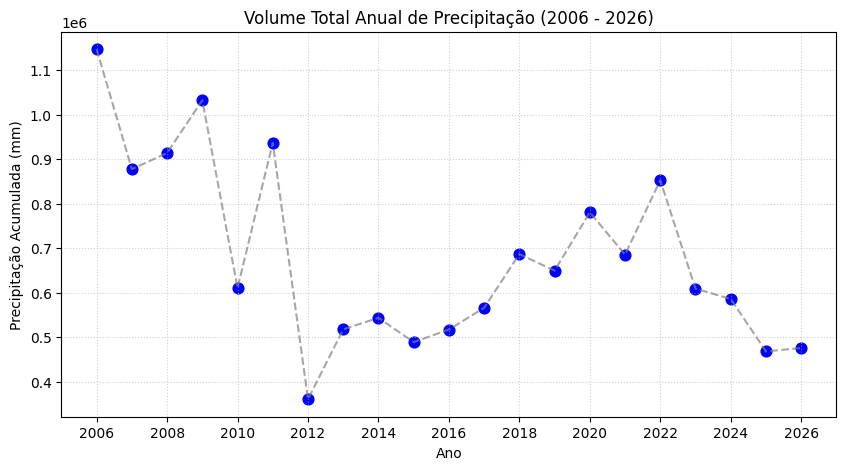

In [17]:
# 1. Garantir que a coluna de data está no formato correto
df_completo['data'] = pd.to_datetime(df_completo['data'])

# 2. Criar a coluna de Ano
df_completo['ano'] = df_completo['data'].dt.year

# 3. Calcular o volume total de chuva por ano
total_anual = df_completo.groupby('ano')['precip_mm'].sum().reset_index()

# 4. Gráfico de dispersão (Scatter Plot) ou Linha Anual
plt.figure(figsize=(10, 5))
plt.scatter(total_anual['ano'], total_anual['precip_mm'], color='blue', s=60)
plt.plot(
    total_anual['ano'],
    total_anual['precip_mm'],
    linestyle='--',
    color='gray',
    alpha=0.7,
)

plt.title('Volume Total Anual de Precipitação (2006 - 2026)')
plt.xlabel('Ano')
plt.ylabel('Precipitação Acumulada (mm)')
plt.xticks(range(2006, 2027, 2))  # Exibe de 2 em 2 anos no eixo X
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## DISTRIBUIÇAO DE FREQUÊNCIAS

### 1.2 UNIVARIAVEL

Tabela de frequencias para variáveis quantitativas

In [18]:
# Calculando a largura do intervalo usando a regra de Sturges

maximo =(df_completo["precip_mm"].max()) #maximo 
minimo =(df_completo["precip_mm"].min()) #minimo
n = len(df_completo["precip_mm"])

k = math.ceil(1 + math.log2(n))
h = (maximo - minimo) / k

print(maximo)
print(minimo)
print(n)
print(f"Número de classes: {k}")
print(f"Tamanho do intervalo: {h}")

1634.727294921875
0.0
750321
Número de classes: 21
Tamanho do intervalo: 77.84415690104167


In [19]:
freq_precip = df_completo["precip_mm"].value_counts(sort=False, bins=k)

print(freq_precip)

(-1.636, 77.844]        609196
(77.844, 155.688]        32862
(155.688, 233.532]       12957
(233.532, 311.377]        5785
(311.377, 389.221]        2851
(389.221, 467.065]        1511
(467.065, 544.909]         773
(544.909, 622.753]         440
(622.753, 700.597]         226
(700.597, 778.442]         128
(778.442, 856.286]          65
(856.286, 934.13]           37
(934.13, 1011.974]          12
(1011.974, 1089.818]        12
(1089.818, 1167.662]         5
(1167.662, 1245.507]         2
(1245.507, 1323.351]         1
(1323.351, 1401.195]         0
(1401.195, 1479.039]         0
(1479.039, 1556.883]         0
(1556.883, 1634.727]         1
Name: count, dtype: int64


Tabela de frequencias para variáveis qualitativas

In [20]:
def tabel_freq_quali(column):
    freq_abs = column.value_counts()
    freq_rel = column.value_counts(normalize=True)

    tabela = pd.DataFrame({
        "Freq absoluta": freq_abs,
        "Freq relativa": freq_rel,
        "Freq relativa (%)": freq_rel * 100,
    })
    tabela.index.name = column.name
    return tabela.reset_index()

col_qualitativas = ["estado", "municipio", "uf", "regiao"]

for i in col_qualitativas:
    print(f"\n-> {i}")
    print(tabel_freq_quali(df_completo[i]).to_string(index=False))


-> estado
             estado  Freq absoluta  Freq relativa  Freq relativa (%)
              Ceará         424424       0.643678          64.367816
              Piauí          83369       0.126437          12.643678
            Paraíba          53053       0.080460           8.045977
Rio Grande do Norte          53053       0.080460           8.045977
         Pernambuco          45474       0.068966           6.896552

-> municipio
                 municipio  Freq absoluta  Freq relativa  Freq relativa (%)
               Jaguaretama          15158       0.022989           2.298851
                Boa Viagem          15158       0.022989           2.298851
         Jacobina do Piauí           7579       0.011494           1.149425
                    Simões           7579       0.011494           1.149425
                  Trindade           7579       0.011494           1.149425
                   Granito           7579       0.011494           1.149425
                     Cedro   

Gráficos

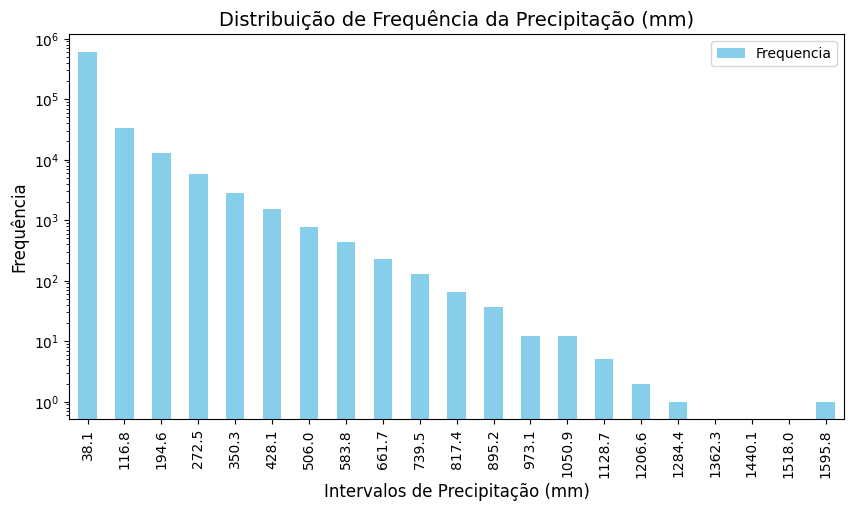

In [21]:
freq_i = df_completo["precip_mm"].value_counts(sort=False, bins=k)

freq_i_data = pd.DataFrame({
    "Intervalo" : freq_i.index.mid.round(1), #que é o ponto médio de cada classe
    "Frequencia" : freq_i.values
})

graph = freq_i_data.plot(x="Intervalo", y="Frequencia", kind="bar", figsize=(10, 5), color='skyblue')

graph.set_title("Distribuição de Frequência da Precipitação (mm)", fontsize=14)
graph.set_xlabel("Intervalos de Precipitação (mm)", fontsize=12)
graph.set_ylabel("Frequência", fontsize=12)
graph.set_yscale("log") #colocando em escala logaritmica no eixo x para 
plt.show()

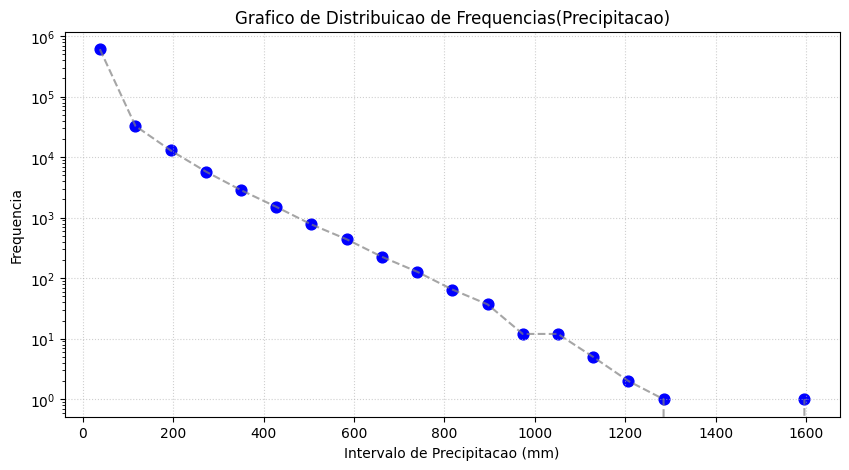

In [22]:
freq_i = df_completo["precip_mm"].value_counts(sort=False, bins= k)

freq_i_data = pd.DataFrame({
    "Intervalo" : freq_i.index.mid,
    "Frequencia" : freq_i.values
})

plt.figure(figsize=(10, 5))
plt.scatter(freq_i_data['Intervalo'], freq_i_data['Frequencia'], color='blue', s=60)
plt.plot(
    freq_i_data['Intervalo'],
    freq_i_data['Frequencia'],
    linestyle='--',
    color='gray',
    alpha=0.7,
)

plt.title('Grafico de Distribuicao de Frequencias(Precipitacao)')
plt.xlabel('Intervalo de Precipitacao (mm)')
plt.ylabel('Frequencia')
plt.yscale("log")

plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### 1.2 BIVARIAVEL

In [23]:
"""
Criação das classes de precipitçaão (df_completo)

-> pd.cut transforma a variável contínua precip_mm em intervalos (classes).
-> include_lowest=True garante que o menor valor entre no primeiro intervalo.

Função que gera as tabelas de frequência bivariada (def tabel_freq_bivariada)

coluna_quali: variável qualitativa (linhas da tabela), ex.: "municipio"
coluna_quanti: variável quantitativa já categorizada (colunas da tabela), ex.: "classe_precip"

"""
df_completo["classe_precip"] = pd.cut(df_completo["precip_mm"],bins=k, include_lowest=True)

def tabel_freq_bivariada(df, coluna_quali, coluna_quanti):
    freq_abs = pd.crosstab( 
        df[coluna_quali], df[coluna_quanti], #combina municipio x classe
        margins=True, margins_name="Total" # acidiona linha e coluna de totais
    )

    freq_rel = pd.crosstab(
        df[coluna_quali], df[coluna_quanti],
        normalize=True
    )* 100

    """
    Cada município vira 100% e você vê como a chuva dele se distribui entre as classes.
    Responde: “Em Fortaleza, qual a proporção de observações com chuva baixa, média ou alta?”
    
    """
    freq_rel_linha = pd.crosstab(
        df[coluna_quali], df[coluna_quanti],
        normalize="index"
    )* 100

    """
    Cada classe de precipitação vira 100% e você vê quanto cada município contribui para ela.
    Responde: “Entre todas as observações de chuva forte 
    (classe mais alta), quantas % vêm de cada município? tipo isso”
    
    """
    freq_rel_coluna = pd.crosstab(
        df[coluna_quali], df[coluna_quanti],
        normalize="columns"
    )* 100

    return freq_abs, freq_rel, freq_rel_linha, freq_rel_coluna

abs_mun, rel_mun, rel_linha_mun, rel_coluna_mun = (
    tabel_freq_bivariada(
        df_completo,
        "municipio",
        "classe_precip"
    )
)

print("\n Frequência absoluta — Município x Precipitação")
print(abs_mun.to_string())

print("\nFrequência relativa conjunta (%)")
print(rel_mun.round(2).to_string())

print("\nDistribuição percentual da precipitação por município (%)")
print(rel_linha_mun.round(2).to_string())

print("\nDistribuição percentual dos municípios por classe de precipitação (%)")
print(rel_coluna_mun.round(2).to_string())


 Frequência absoluta — Município x Precipitação
classe_precip               (-1.636, 77.844]  (77.844, 155.688]  (155.688, 233.532]  (233.532, 311.377]  (311.377, 389.221]  (389.221, 467.065]  (467.065, 544.909]  (544.909, 622.753]  (622.753, 700.597]  (700.597, 778.442]  (778.442, 856.286]  (856.286, 934.13]  (934.13, 1011.974]  (1011.974, 1089.818]  (1089.818, 1167.662]  (1167.662, 1245.507]  (1245.507, 1323.351]  (1556.883, 1634.727]   Total
municipio                                                                                                                                                                                                                                                                                                                                                                                                       
Acaraú                                  6790                454                 191                  72                  31                  15      

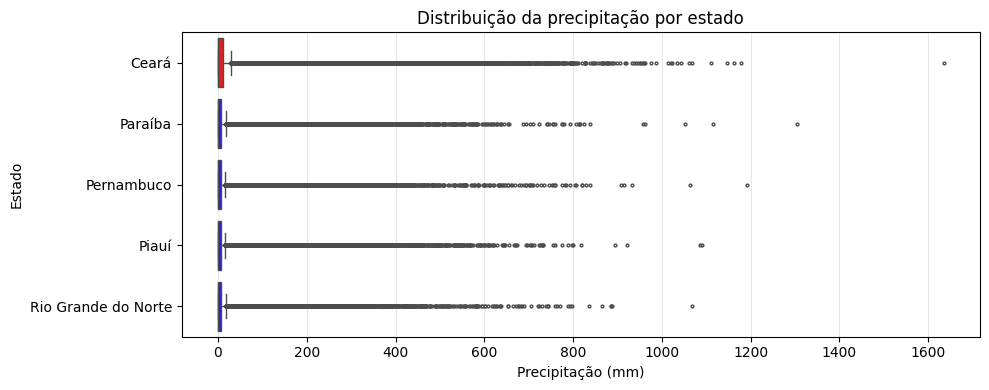

                     quantidade  media  mediana  desvio_padrao  minimo   maximo
estado                                                                         
Ceará                    424368  22.81      0.0          61.27     0.0  1634.73
Paraíba                   53046  19.78      0.0          59.61     0.0  1303.61
Pernambuco                45468  18.01      0.0          56.75     0.0  1192.31
Piauí                     83358  18.40      0.0          54.47     0.0  1090.33
Rio Grande do Norte       53046  18.32      0.0          54.50     0.0  1068.78


In [ ]:

"""
Boxplot horizontal de precipitação por estado, com um estado em destaque
-> min_obs: descarta estados com poucas observações
-> sem_zeros: se True, considera só precip_mm > 0 (dias com chuva)

"""

def boxplot_precip_estado(
    df,
    destaque="Ceará",
    coluna_estado="estado",
    coluna_valor="precip_mm",
    min_obs=30,
    sem_zeros=False,
    salvar=None
):

    datas = df[[coluna_estado, coluna_valor]].dropna()      # mantém só as 2 colunas e remove linhas com nan

    if sem_zeros:                                           # se pediu para ignorar dias sem chuva
        datas = datas[datas[coluna_valor] > 0]              # mantém só observações com chuva

    count = datas[coluna_estado].value_counts()             # número de observações de cada estado

    datas = datas[
        datas[coluna_estado].isin(count[count >= min_obs].index)  # mantém só estados com pelo menos min_obs observações
    ]

    ordem = (
        datas.groupby(coluna_estado)[coluna_valor]          # agrupa a precipitação por estado
        .median()                                           # calcula a mediana de cada estado
        .sort_values()                                      # ordena do menor ao maior
        .index.tolist()                                     # lista com os nomes dos estados na ordem
    )

    resumo_estados = (
        datas.groupby(coluna_estado)[coluna_valor]          # agrupa a precipitação por estado
        .agg(
            quantidade="count",                             # número de observações
            media="mean",                                   # média da precipitação
            mediana="median",                               # mediana da precipitação
            desvio_padrao="std",                            # desvio-padrão da precipitação
            minimo="min",                                   # menor valor de precipitação
            maximo="max"                                    # maior valor de precipitação
        )
        .reindex(ordem)                                     # mantém a mesma ordem do boxplot
        .round(2)                                           # arredonda para 2 casas decimais
    )

    paleta = {
        estado: ("red" if estado == destaque else "blue")   # destaque vermelho, demais azuis
        for estado in ordem                                 # dicionário estado -> cor
    }

    fig, graph = plt.subplots(
        figsize=(10, max(4, 0.45 * len(ordem)))             # altura cresce com o nº de estados (mínimo de 4 polegadas)
    )

    sns.boxplot(
        data=datas,                                         # dados filtrados
        y=coluna_estado,                                    # estado no eixo y
        x=coluna_valor,                                     # precipitação no eixo x
        order=ordem,                                        # ordem por mediana
        hue=coluna_estado,                                  # colore por estado
        hue_order=ordem,                                    # mesma ordem nas cores
        palette=paleta,                                     # cores definidas acima
        legend=False,                                       # esconde a legenda redundante
        orient="h",                                         # boxplot horizontal
        fliersize=2,                                        # tamanho dos outliers
        linewidth=1,                                        # espessura das linhas
        ax=graph                                            # desenha no eixo criado
    )

    graph.set_title("Distribuição da precipitação por estado")  # título do gráfico
    graph.set_xlabel("Precipitação (mm)")                   # rótulo do eixo x
    graph.set_ylabel("Estado")                              # rótulo do eixo y
    graph.grid(axis="x", alpha=0.3)                         # grade vertical leve (alpha = transparência)

    plt.tight_layout()                                      # ajusta margens para nada ficar cortado

    if salvar:                                              # se um caminho foi informado
        plt.savefig(salvar, dpi=300, bbox_inches="tight")   # salva a figura (dpi = resolução)

    plt.show()                                              # exibe o gráfico na tela

    return resumo_estados                                   # retorna a tabela para uso fora da função


resumo_estados = boxplot_precip_estado(                     # chama a função e recebe a tabela de estatísticas
    df_completo,                                            # dataframe com os dados
    destaque="Ceará",                                       # estado em destaque
    min_obs=30,                                             # mínimo de observações por estado
    sem_zeros=False,                                        # usa todas as observações, inclusive zeros
    escala_log=False,                                       # eixo x em escala linear
    salvar="boxplot_precip_estado.png"                      # nome do arquivo de saída
)

print(resumo_estados.to_string())                           # imprime a tabela inteira, sem truncar


### 1.4 MEDIDA DE POSICAO

In [ ]:
def medida_posicao(df: pd.DataFrame):
    """
    Calcula medidas de posição para a coluna 'precip_mm', maiores que zero, do DataFrame fornecido.
    
    Parâmetros:
    df (pd.DataFrame): DataFrame contendo a coluna 'precip_mm'.
    
    Retorna:
    dict: Um dicionário contendo as medidas de posição.
    """
    chuva = df_completo.loc[df_completo["precip_mm"] > 0, "precip_mm"]

    media = chuva.mean()
    mediana = chuva.median()
    moda = chuva.mode()[0]  # Pega o primeiro valor da moda
    minimo = chuva.min()
    maximo = chuva.max()
    
    return {
        "Média": media,
        "Mediana": mediana,
        "Moda": moda,
        "Mínimo": minimo,
        "Máximo": maximo
    }

In [ ]:
def medida_dispersao(df: pd.DataFrame):
    """
    Calcula medidas de dispersão para a coluna 'precip_mm', maiores que zero, do DataFrame fornecido.
    
    Parâmetros:
    df (pd.DataFrame): DataFrame contendo a coluna 'precip_mm'.
    
    Retorna:
    dict: Um dicionário contendo as medidas de dispersão.
    """
    chuva = df_completo.loc[df_completo["precip_mm"] > 0, "precip_mm"]

    variancia = chuva.mean()
    mediana = chuva.median()
    moda = chuva.mode()[0]  # Pega o primeiro valor da moda
    minimo = chuva.min()
    maximo = chuva.max()
    
    return {
        "Média": media,
        "Mediana": mediana,
        "Moda": moda,
        "Mínimo": minimo,
        "Máximo": maximo
    }

In [ ]:
medidas_posicao = medida_posicao(df_completo)
print("Medidas de Posição para a coluna 'precip_mm':")
for medida, valor in medidas_posicao.items():
    print(f"{medida}: {valor}")

Medidas de Posição para a coluna 'precip_mm':
Média: 48.98001553287524
Mediana: 15.33854150772095
Moda: 0.2985477447509766
Mínimo: 0.0286579076200723
Máximo: 1634.727294921875


Medidas de posicao para variaveis qualitativas

In [ ]:
def iqv(freq):
    k = freq.value_counts(normalize=True)
    n = len(k)
    if n < 2:
        return 0

    iqv_value = (n / (n - 1)) * (1 - (k**2).sum())
    return iqv_value


In [ ]:
iqv_estado = iqv(df_completo["estado"])
iqv_municipio = iqv(df_completo["municipio"])
iqv_uf = iqv(df_completo["uf"])
iqv_regiao = iqv(df_completo["regiao"])
iqv_precip_mm = iqv(df_completo["precip_mm"])

tabela_iqv = pd.DataFrame({
    "Variável": ["estado", "municipio", "uf", "regiao", "precip_mm"],
    "IQV" : [iqv_estado, iqv_municipio, iqv_uf, iqv_regiao, iqv_precip_mm]
})

print(tabela_iqv)

    Variável       IQV
0     estado  0.689985
1  municipio  0.999739
2         uf  0.689985
3     regiao  0.000000
4  precip_mm  0.684336
